# SmartRecon: nghiên cứu đối soát tài chính

## 1. Giới thiệu bài toán
Notebook đánh giá việc liên kết hai feed nghiệp vụ độc lập: khoản phải thu và giao dịch ngân hàng/PSP. Các quan hệ 1:1, nhiều đơn–một giao dịch (N:1) và một đơn–nhiều giao dịch (1:N) cần được biểu diễn bằng cạnh phân bổ tiền. Ground truth tách khỏi input runtime giúp đo chất lượng mà không tiết lộ đáp án cho engine. Phạm vi là dữ liệu synthetic VND; kết quả không phải bảo đảm cho dữ liệu ngân hàng thực hoặc mọi miền dữ liệu.

In [1]:
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from scripts.run_evaluation import evaluate as run_evaluation
from smartrecon.config import ReconciliationPolicy
from smartrecon.domain.statuses import Currency, OrderStatus
from smartrecon.engine import run_reconciliation
from smartrecon.evaluation.experiments import ablation_results
from smartrecon.evaluation.ground_truth import load_ground_truth
from smartrecon.evaluation.metrics import evaluate_result
from smartrecon.ingest.mapping import default_demo_mapping
from smartrecon.ingest.normalization import normalize_bundle
from smartrecon.ingest.readers import read_source_bundle

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data" / "demo" / "vn_synthetic_demo"
SEED = 20261016
POLICY = ReconciliationPolicy(currency=Currency.VND)
print({"python": platform.python_version(), "seed": SEED, "rule_version": POLICY.rule_version})

{'python': '3.12.14', 'seed': 20261016, 'rule_version': '2026-10-15'}


## 2. Nguồn dữ liệu
Bộ dữ liệu được sinh hoàn toàn, gồm feed khoản phải thu và feed giao dịch bank/PSP mô phỏng; không phải sao kê thật. Nhãn `truth_edges` và `truth_cases` chỉ được evaluator đọc. Repo không kèm dữ liệu Olist-derived BRL nên notebook không gắn nhãn nguồn Olist cho dữ liệu thay thế. Manifest lưu seed, schema counts và semantic SHA-256 hashes.

In [2]:
manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
truth = load_ground_truth(DATA_DIR)
development_truth = truth.subset("development")
holdout_truth = truth.subset("holdout")
pd.DataFrame(
    {
        "value": [manifest["profile"], manifest["seed"], len(development_truth.edges), len(holdout_truth.edges)],
    },
    index=["profile", "seed", "development truth edges", "holdout truth edges"],
)
print(json.dumps(manifest["semantic_hashes"], indent=2))

{
  "bank_transactions": "3cd11469c60e96c8637800384e5289ddab8866b90fb55fb2439ce2c87b0ec65e",
  "orders": "623eabee01004bdf26e694aa4d11ecdb861093151bb5588c73e4abfbcaa33614",
  "truth_cases": "08d358aa177eaba5720cb35aed6857650f765cd81dcc87d8d859d8d6638b61c7",
  "truth_edges": "48648e08b8f5f302418881a2392ddd64e3144bd17082fd8b7f789806f9ea0341"
}


## 3. Exploratory Data Analysis
Các bảng và biểu đồ dưới đây được tính trực tiếp từ hai CSV business. Kiểm tra gồm kích thước, missing, trùng ID, phân bố tiền/ngày và direction; các ngoại lệ nghiệp vụ chi tiết được engine phân loại ở phần sau.

,feed,rows,columns,missing,duplicate_ids
0,orders,100,9,0,0
1,bank,98,13,195,0


,rows
direction,
CREDIT,97
DEBIT,1


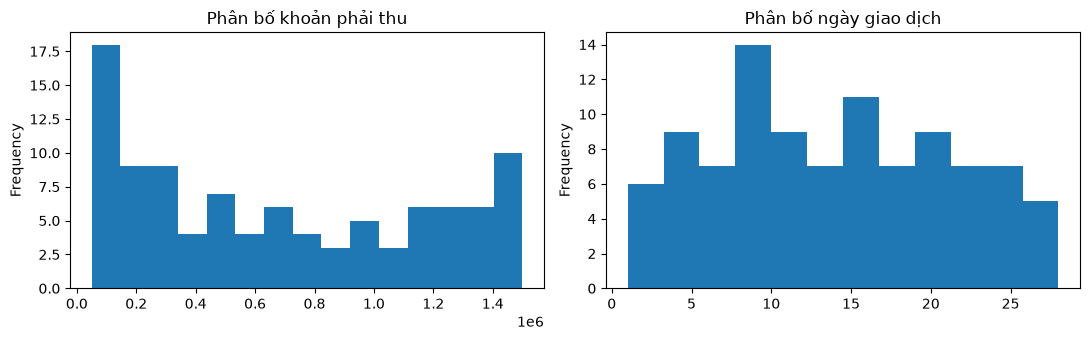

In [3]:
orders_frame = pd.read_csv(
    DATA_DIR / "internal_receivables.csv", dtype={"order_id": "string", "external_ref": "string"}
)
banks_frame = pd.read_csv(DATA_DIR / "bank_transactions.csv", dtype={"bank_txn_id": "string", "txn_ref": "string"})
eda_summary = pd.DataFrame(
    [
        {
            "feed": "orders",
            "rows": len(orders_frame),
            "columns": len(orders_frame.columns),
            "missing": int(orders_frame.isna().sum().sum()),
            "duplicate_ids": int(orders_frame.order_id.duplicated().sum()),
        },
        {
            "feed": "bank",
            "rows": len(banks_frame),
            "columns": len(banks_frame.columns),
            "missing": int(banks_frame.isna().sum().sum()),
            "duplicate_ids": int(banks_frame.bank_txn_id.duplicated().sum()),
        },
    ]
)
display(eda_summary)
display(banks_frame["direction"].value_counts(dropna=False).rename_axis("direction").to_frame("rows"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
orders_frame["expected_amount"].plot.hist(bins=15, ax=axes[0], title="Phân bố khoản phải thu")
pd.to_datetime(banks_frame["txn_date"]).dt.day.plot.hist(bins=12, ax=axes[1], title="Phân bố ngày giao dịch")
plt.tight_layout()
plt.show()

## 4. Data preprocessing
Adapter dùng mapping được xác nhận, chuẩn hóa ngày và reference rồi parse tiền bằng `Decimal` sang integer minor units. Với VND, phần thập phân khác 0 là lỗi blocking và không được làm tròn. Normalized bundle dưới đây chính là input của public core API; truth không được truyền vào.

In [4]:
raw = read_source_bundle(
    orders_path=DATA_DIR / "internal_receivables.csv", bank_path=DATA_DIR / "bank_transactions.csv"
)
normalized = normalize_bundle(raw, default_demo_mapping())
print(
    {
        "normalized_orders": len(normalized.orders),
        "normalized_bank_rows": len(normalized.bank_transactions),
        "duplicate_bank_ids": len(normalized.duplicate_bank_ids),
    }
)

{'normalized_orders': 100, 'normalized_bank_rows': 98, 'duplicate_bank_ids': 1}


## 5. Waterfall Matching
Public engine chạy L1 strong reference, L2 policy-constrained, L3 fuzzy candidate và L4 bounded group/split. L2/L3/L4 thiếu bằng chứng độc lập vẫn chỉ tạo proposal. Biểu đồ lấy số đếm thật từ result, không đặt trước expected chart values.

,confirmed_groups,proposed_groups
L1,38,0
L2,51,4
L3,0,1
L4,0,4


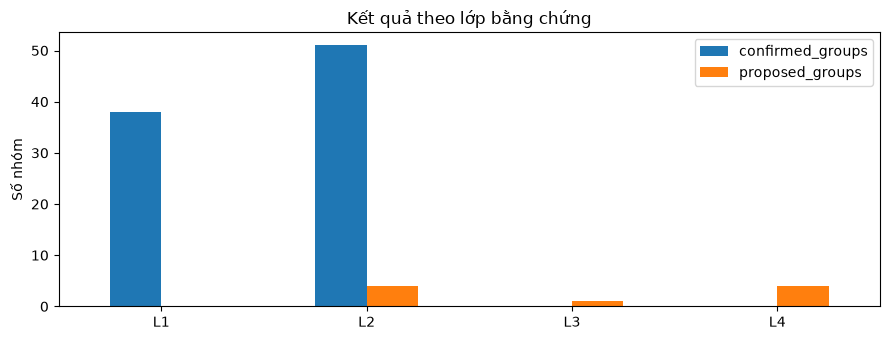

{'semantic_checksum': 'f3bd243a850d7dac55f5b544679d9c96eb98cd30925dcd010945c24f5baeffd8', 'confirmed_allocations': 91, 'proposals': 9, 'exceptions': 22}


In [5]:
result = run_reconciliation(normalized, POLICY)
layer_frame = pd.DataFrame(result.layer_counts).T.fillna(0).astype(int)
display(layer_frame)
layer_frame.plot(kind="bar", figsize=(9, 3.5), title="Kết quả theo lớp bằng chứng")
plt.ylabel("Số nhóm")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print(
    {
        "semantic_checksum": result.semantic_checksum,
        "confirmed_allocations": len(result.allocations),
        "proposals": len(result.candidates),
        "exceptions": len(result.exceptions),
    }
)

## 6. Group/Split Matching
Group cardinality cho biết quan hệ 1:1, N:1 và 1:N. Partial/overpayment giữ residual rõ ràng; verified PSP fee là adjustment có chứng cứ, không phải khoản xóa sổ tự suy diễn.

In [6]:
group_rows = [
    {
        "group_id": group.group_id,
        "orders": len(group.order_ids),
        "banks": len(group.bank_txn_ids),
        "link_status": group.link_status.value,
        "review_status": group.review_status.value,
        "rule": group.evidence.rule_id,
    }
    for group in result.groups
]
groups_frame = pd.DataFrame(group_rows)
display(groups_frame.groupby(["orders", "banks", "link_status"]).size().rename("groups").reset_index())
display(
    pd.Series(
        {
            status.value: list(result.payment_statuses.values()).count(status)
            for status in set(result.payment_statuses.values())
        },
        name="orders",
    )
)

,orders,banks,link_status,groups
0,1,1,CONFIRMED,87
1,1,1,PROPOSED,4
2,1,2,CONFIRMED,1
3,2,1,CONFIRMED,1
4,2,1,PROPOSED,1
5,2,2,PROPOSED,1
6,3,1,PROPOSED,3


FULL                    87
PARTIAL                  2
NO_CONFIRMED_RECEIPT     3
UNKNOWN                  7
OVERPAID                 1
Name: orders, dtype: int64

## 7. Conservation Analysis
Oracle bảo toàn độc lập đối chiếu từng bank/order và toàn run: bank credit = allocated + unapplied; receivable = allocated + verified adjustment + outstanding. Allocation amount được cộng từ edges thay vì KPI hiển thị.

In [7]:
allocated = sum(edge.allocated_cash_minor for edge in result.allocations)
adjusted = sum(item.amount_minor for item in result.adjustments)
bank_by_id = {bank.bank_txn_id: bank for bank in result.bank_transactions}
bank_credit = sum(bank_by_id[bank_id].eligible_credit_minor for bank_id in result.conservation.bank_unapplied)
receivables = sum(order.expected_amount_minor for order in result.orders if order.order_status is OrderStatus.ELIGIBLE)
conservation_table = pd.DataFrame(
    [
        {
            "identity": "bank",
            "source_minor": bank_credit,
            "components_minor": allocated + sum(result.conservation.bank_unapplied.values()),
        },
        {
            "identity": "orders",
            "source_minor": receivables,
            "components_minor": allocated + adjusted + sum(result.conservation.order_outstanding.values()),
        },
    ]
)
conservation_table["difference_minor"] = conservation_table.source_minor - conservation_table.components_minor
display(conservation_table)
assert result.conservation.is_valid and not conservation_table.difference_minor.any()

,identity,source_minor,components_minor,difference_minor
0,bank,67536000,67536000,0
1,orders,67865000,67865000,0


## 8. Evaluation
Holdout được chọn bằng parity của byte đầu SHA-256 của `case_id`, độc lập với prediction và label values. Precision/Recall/F1 tính trên confirmed edges; proposal chỉ tham gia candidate retrieval. Allocation error so sánh integer minor units. Mẫu số 0 được báo `None` (N/A).

In [8]:
holdout_metrics = evaluate_result(result, holdout_truth)
metric_table = pd.DataFrame(
    {
        "metric": [
            "edge precision",
            "edge recall",
            "edge F1",
            "group precision",
            "group recall",
            "candidate recall",
            "auto-confirm coverage",
            "false auto-confirm rate",
            "allocation MAE minor",
        ],
        "value": [
            holdout_metrics.edge_precision.value,
            holdout_metrics.edge_recall.value,
            holdout_metrics.edge_f1,
            holdout_metrics.group_precision.value,
            holdout_metrics.group_recall.value,
            holdout_metrics.candidate_recall.value,
            holdout_metrics.auto_confirm_coverage.value,
            holdout_metrics.false_auto_confirm_rate.value,
            holdout_metrics.allocation_mae_minor,
        ],
    }
)
display(metric_table)
display(pd.DataFrame(holdout_metrics.per_relation).T)

,metric,value
0,edge precision,1.000000
1,edge recall,0.914894
2,edge F1,0.955556
3,group precision,1.000000
4,group recall,0.934783
5,candidate recall,1.000000
6,auto-confirm coverage,0.914894
7,false auto-confirm rate,0.000000
8,allocation MAE minor,14893.617021


,truth_edges,confirmed_precision,confirmed_recall,candidate_precision,candidate_recall
MANY_ORDERS_ONE_BANK,2.0,NaN,0.000000,0.400000,1.0
ONE_TO_ONE,45.0,1.0,0.955556,0.918367,1.0


## 9. Ablation Study và hard benchmark
Ablation lọc output theo public rule IDs trên cùng run/truth; nó đo đóng góp của retrieval/confirmation mà không triển khai engine thứ hai. Benchmark tái sinh profile 1.000 orders bằng seed, ghi hashes, policy, commit, runtime và peak Python allocations. Profile giữ bộ hard cases đã định nghĩa và tăng tải bằng exact fillers; vì vậy đây là kiểm tra tải tái lập, chưa đại diện tỷ lệ ambiguity ngoài thực tế.

,variant,layers,edge_precision,edge_recall,edge_f1,auto_confirm_coverage,false_auto_confirm_count,candidate_precision,candidate_recall
0,Exact-reference baseline,[L1],1.0,0.382979,0.553846,0.382979,0,1.000000,0.382979
1,Reference + constrained,"[L1, L2]",1.0,0.914894,0.955556,0.914894,0,0.956522,0.936170
2,Add fuzzy candidates,"[L1, L2, L3]",1.0,0.914894,0.955556,0.914894,0,0.957447,0.957447
3,Add bounded group/split candidates,"[L1, L2, L3, L4]",1.0,0.914894,0.955556,0.914894,0,0.903846,1.000000
4,Full waterfall,"[L1, L2, L3, L4, resolver, allocation]",1.0,0.914894,0.955556,0.914894,0,0.903846,1.000000


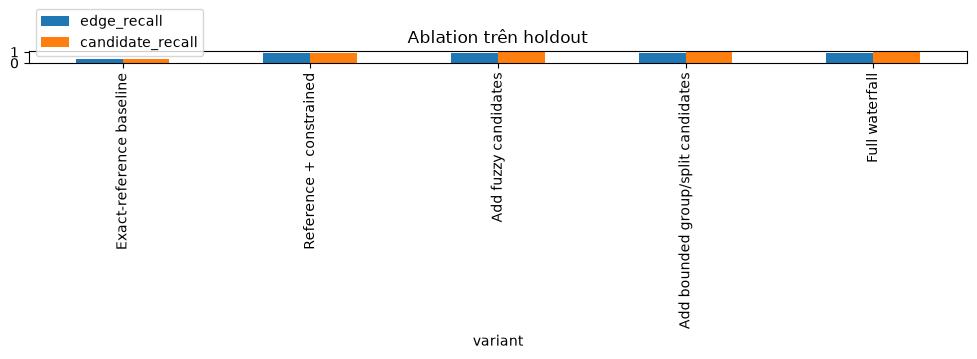

,profile,seed,orders,bank_transactions,elapsed_seconds,peak_tracemalloc_bytes,commit
0,seeded synthetic VND with hard cases and exact...,20261016,1000,998,5.067196,9609065,30c88c7523b0ae091db1b467d3fb847c6ded9e0a


,numerator,denominator,value
precision,507,507,1.000000
recall,507,511,0.992172


In [9]:
ablation_frame = pd.DataFrame(ablation_results(result, holdout_truth))
display(ablation_frame)
ablation_frame.set_index("variant")[["edge_recall", "candidate_recall"]].plot(
    kind="bar", figsize=(10, 3.5), ylim=(0, 1.05), title="Ablation trên holdout"
)
plt.tight_layout()
plt.show()
evaluation = run_evaluation(order_count=1000, seed=SEED)
display(pd.DataFrame([evaluation["benchmark"]]).drop(columns=["dataset_hashes", "policy", "metrics", "hardware"]))
display(
    pd.DataFrame(
        [evaluation["benchmark"]["metrics"]["edge_precision"], evaluation["benchmark"]["metrics"]["edge_recall"]],
        index=["precision", "recall"],
    )
)

## 10. Kết luận nghiên cứu
Kết luận phải đọc từ các bảng phía trên. Trên synthetic holdout hiện tại, xác nhận tự động ưu tiên precision và giữ ambiguous/group thiếu chứng cứ ở proposal; candidate retrieval tăng recall mà không biến proposal thành confirmed cash. Điểm yếu là tỷ lệ filler exact cao, bộ nhãn nhỏ cho N:1/1:N và không có observed Olist/real bank feed. Chưa có bằng chứng cho accuracy hoặc throughput ở miền dữ liệu thực, quy mô 10k+, FX, M:N tổng quát hay public multi-user deployment. Bước nghiên cứu tiếp theo hợp lệ là mở rộng hard-case distribution độc lập và khóa holdout trước khi hiệu chỉnh policy.

In [10]:
print(
    {
        "holdout_edge_precision": holdout_metrics.edge_precision.value,
        "holdout_edge_recall": holdout_metrics.edge_recall.value,
        "holdout_edge_f1": holdout_metrics.edge_f1,
        "false_auto_confirm_count": holdout_metrics.false_auto_confirm_count,
        "allocation_error_minor": holdout_metrics.allocation_total_absolute_error_minor,
        "benchmark_seconds": evaluation["benchmark"]["elapsed_seconds"],
    }
)

{'holdout_edge_precision': 1.0, 'holdout_edge_recall': 0.9148936170212766, 'holdout_edge_f1': 0.9555555555555556, 'false_auto_confirm_count': 0, 'allocation_error_minor': 700000, 'benchmark_seconds': 5.067196199997852}
